# Lab 06: How to share tools with MCP

**Notebook 2 of 2: MCP at the Chinook desk**

## Goal

Take MCP to a real job: the support desk of the Chinook music shop, where a rep asks about a customer and an agent
looks the facts up in the shop's database. We answer one question with three lookups that live in this notebook.
Then we delete those three lookups, and a program we did not write, the OpenAI Agents SDK, answers the same
question through a server file that we do not edit. The lookups are written once, in one file, and a program whose
authors never saw that file uses them.

## What you will learn

- How to read an MCP server file for a real job: three database lookups with typed parameters and typed results.
- How the server builds each tool's description and schema from the function, while our own loop needs them
  typed by hand.
- How to call the server with the official client and read a result, including a lookup that finds nobody.
- How to give the same server to an agent framework with a few lines, and check that its answer came from the
  server's tools.

## From the playground to the desk

In notebook 1 we met MCP on a shopping list. Three things carry over:

- An **MCP server** is a Python file that runs as its own program. `@mcp.tool()` above a typed function turns it
  into a tool.
- A **client** starts the server and asks it two things: which tools do you have (`list_tools`), and run this one
  with these arguments (`call_tool`).
- A **host** is the program that holds the conversation with the model. It tells the model which tools exist and
  sends the model's tool calls to the server.

Now we take it seriously. The tools read a shop's database, and a rep will repeat the answers to a customer. This
notebook restates everything it uses, so it runs on its own.

## Setup

The first cell is the same in every lab: it finds the repository folder, reads the model name from `models.env`, and
takes the key from `.env` without printing it. This notebook adds `json`, `sqlite3` and `sys` from Python's standard
library.

In [1]:
from pathlib import Path
import json
import os
import sqlite3
import sys
from dotenv import dotenv_values

# The repository folder is the first folder, from here upwards, that holds models.env
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "models.env").exists())

# Models and prices come from models.env; a non-empty value in .env replaces one of them
settings = dotenv_values(ROOT / "models.env")
local = dotenv_values(ROOT / ".env")
settings.update({name: value for name, value in local.items() if name in settings and value})

# The key comes from the environment or .env, and is never printed
os.environ.setdefault("OPENAI_API_KEY", local.get("OPENAI_API_KEY") or "")
assert os.environ["OPENAI_API_KEY"], "Put OPENAI_API_KEY in .env at the repository folder (copy .env.example)."

MODEL = settings["MODEL_DEFAULT"]
EFFORT = settings["REASONING_EFFORT"] or None
print("model:", MODEL, "| reasoning effort:", EFFORT, "| key found: yes")

model: gpt-6-luna | reasoning effort: none | key found: yes


---

## Part A: Answer a desk question with three lookups that live in this notebook

The shop's data is `data/chinook.db`, a SQLite file with the customers, their invoices and the support reps who
look after them. A rep at the desk asks things like:

> How many invoices does Helena Holý have, what do they add up to, and who is her support rep?

The question asks for three facts, and they are in three tables. We write one small function for each lookup and
call them ourselves first, so we know the right answers before any model is involved.

### The three lookups

- `find_customer(name)` finds a customer by full name and returns their `customer_id`.
- `get_invoices(customer_id)` counts that customer's invoices and adds up their total.
- `get_support_rep(customer_id)` names the rep who looks after them.

`mode=ro` in the first lines opens the database **read-only**, so no lookup can change the shop's data. `uri=True`
tells `connect` to read the path as a URI (it starts with `file:`), which is how it reads the `?mode=ro` setting at
the end. `check_same_thread=False` allows the connection to be used from another thread; this notebook does not need
it, and keeps it so the line matches the one in `chinook_server.py`.

In [2]:
DB_PATH = ROOT / "data" / "chinook.db"
conn = sqlite3.connect(f"file:{DB_PATH}?mode=ro", uri=True, check_same_thread=False)


def find_customer(name: str) -> list[dict]:
    """Find a Chinook customer by full name. Returns a list of matches, each with its customer_id."""
    rows = conn.execute(
        "SELECT CustomerId, FirstName || ' ' || LastName, Country FROM customers "
        "WHERE FirstName || ' ' || LastName = ?", (name,)).fetchall()
    return [{"customer_id": r[0], "name": r[1], "country": r[2]} for r in rows]


def get_invoices(customer_id: int) -> dict:
    """Count a customer's invoices and add up their total in US dollars."""
    count, total = conn.execute(
        "SELECT COUNT(*), ROUND(SUM(Total), 2) FROM invoices WHERE CustomerId = ?", (customer_id,)).fetchone()
    return {"customer_id": customer_id, "invoice_count": count, "total": total}


def get_support_rep(customer_id: int) -> dict:
    """Name the support rep assigned to a customer."""
    row = conn.execute(
        "SELECT e.FirstName || ' ' || e.LastName FROM customers c "
        "JOIN employees e ON e.EmployeeId = c.SupportRepId WHERE c.CustomerId = ?", (customer_id,)).fetchone()
    return {"customer_id": customer_id, "support_rep": row[0] if row else None}

We look Helena up by hand.

In [3]:
customer = find_customer("Helena Holý")[0]

print(customer)
print(get_invoices(customer["customer_id"]))
print(get_support_rep(customer["customer_id"]))

{'customer_id': 6, 'name': 'Helena Holý', 'country': 'Czech Republic'}
{'customer_id': 6, 'invoice_count': 7, 'total': 49.62}
{'customer_id': 6, 'support_rep': 'Steve Johnson'}


These are the facts every answer in this notebook is checked against:

| Customer | `customer_id` | Invoices | Total | Support rep |
|---|---|---|---|---|
| Helena Holý | 6 | 7 | \$49.62 | Steve Johnson |

**Notice** the order the lookups need. `get_invoices` and `get_support_rep` take a `customer_id`, and only
`find_customer` can supply it.

### Describe the lookups to the model, by hand

A model never sees our Python. To let it ask for a lookup, we describe each one in the request, in the format the
Chat Completions API expects: a `name`, a `description`, and the `parameters` as a JSON Schema. We write the three
descriptions ourselves.

`FUNCTIONS` maps each tool name to the Python function that does the work, so our code can find the function when
the model writes its name.

Read the first entry closely. The other two have the same shape; only the name, the description and the one
parameter change.

In [4]:
TOOLS = [
    {
        "type": "function",
        "function": {
            "name": "find_customer",
            "description": "Find a Chinook customer by full name. Returns a list of matches, each with its customer_id.",
            "parameters": {
                "type": "object",
                "properties": {"name": {"type": "string"}},
                "required": ["name"],
            },
        },
    },
    {
        "type": "function",
        "function": {
            "name": "get_invoices",
            "description": "Count a customer's invoices and add up their total in US dollars.",
            "parameters": {
                "type": "object",
                "properties": {"customer_id": {"type": "integer"}},
                "required": ["customer_id"],
            },
        },
    },
    {
        "type": "function",
        "function": {
            "name": "get_support_rep",
            "description": "Name the support rep assigned to a customer.",
            "parameters": {
                "type": "object",
                "properties": {"customer_id": {"type": "integer"}},
                "required": ["customer_id"],
            },
        },
    },
]

FUNCTIONS = {"find_customer": find_customer, "get_invoices": get_invoices, "get_support_rep": get_support_rep}

A long cell, and it repeats what the functions already say: each name, each docstring, each parameter and its type.
If a function changes, its description has to be changed by hand as well.

### The tool loop, with the lookups in this notebook

The loop is the one from notebook 1, written on Chat Completions, the basic request-and-reply API:

1. Send the conversation and the tool descriptions to the model.
2. If the reply has no tool calls, it is the answer: return it.
3. Otherwise run each call and add the result to the conversation as a `tool` message.
4. Go back to step 1, at most five times.

Step 3 is the line to look at: `FUNCTIONS[call.function.name](**arguments)` finds the Python function by its name
and runs it, here, in this notebook's process. `**arguments` passes `{"customer_id": 6}` as `customer_id=6`.

`OpenAI(timeout=60)` gives up on a request after 60 seconds, and `reasoning_effort=EFFORT or omit` passes the
reasoning effort from `models.env`, or leaves it out when that setting is empty.

In [5]:
from openai import OpenAI, omit

client = OpenAI(timeout=60)

INSTRUCTIONS = (
    "You help the support reps of a music shop. Look up every fact with the tools; "
    "never answer from memory. Answer in one or two sentences."
)


def ask(question, max_turns=5):
    messages = [{"role": "system", "content": INSTRUCTIONS}, {"role": "user", "content": question}]

    for turn in range(max_turns):
        response = client.chat.completions.create(
            model=MODEL,
            messages=messages,
            tools=TOOLS,
            reasoning_effort=EFFORT or omit,
        )
        reply = response.choices[0].message
        if not reply.tool_calls:
            return reply.content

        messages.append(reply)
        for call in reply.tool_calls:
            arguments = json.loads(call.function.arguments)
            result = FUNCTIONS[call.function.name](**arguments)
            print("NOTEBOOK FUNCTION CALLED:", call.function.name, arguments)
            messages.append({"role": "tool", "tool_call_id": call.id, "content": json.dumps(result, ensure_ascii=False)})

    return "No answer after " + str(max_turns) + " turns."

Now the model gets Helena's question, with the three tool descriptions.

In [6]:
HELENA = "How many invoices does Helena Holý have, what do they add up to, and who is her support rep?"

print(ask(HELENA))

NOTEBOOK FUNCTION CALLED: find_customer {'name': 'Helena Holý'}


NOTEBOOK FUNCTION CALLED: get_invoices {'customer_id': 6}
NOTEBOOK FUNCTION CALLED: get_support_rep {'customer_id': 6}


Helena Holý has 7 invoices totaling $49.62. Her support rep is Steve Johnson.


Three `NOTEBOOK FUNCTION CALLED` lines, then the answer: 7 invoices, \$49.62 and Steve Johnson, as in the table.
The model asked for `find_customer` first, because the other two lookups need the `customer_id` it returns. Each
call ran as a Python function in this notebook.

### What is tied to this notebook

The agent works, and three things about it exist only here:

- the three functions, in this notebook's memory;
- the three descriptions in `TOOLS`, typed by hand;
- `FUNCTIONS`, the dictionary that connects a name to a function.

Another program that needs the same lookups (a second notebook, an agent framework, the chat page of the support
team) would need its own copy of all three. Part B moves the lookups to a place where every program can reach them.

**Checkpoint A.** By hand: customer 6 in the Czech Republic, 7 invoices, 49.62, Steve Johnson. The loop prints three
`NOTEBOOK FUNCTION CALLED` lines, `find_customer` first, and its answer has the same three facts.

---

## Part B: Read the same three lookups in a server file

The lab comes with `chinook_server.py`, beside this notebook: the three lookups as an MCP server. We print it
before we run it. Starting a server means running its code on your machine with your permissions, so we read it
first.

In [7]:
SERVER_FILE = ROOT / "06_MCP" / "chinook_server.py"

print(SERVER_FILE.read_text())

"""The three Chinook lookups as an MCP server, run over stdio.

Lab 06 starts this file as its own process; a host can start it the same way:
    python 06_MCP/chinook_server.py
It then reads JSON-RPC messages from stdin and writes its replies to stdout, one per line.
"""

import sqlite3
from pathlib import Path
from typing import TypedDict

from mcp.server import MCPServer

# The repository folder is the first folder above this file that holds data/chinook.db
ROOT = next(p for p in Path(__file__).resolve().parents if (p / "data" / "chinook.db").exists())
DB = ROOT / "data" / "chinook.db"

# Read-only: every write fails, whatever a host asks for
con = sqlite3.connect(f"file:{DB}?mode=ro", uri=True, check_same_thread=False)

mcp = MCPServer("chinook")


# The shapes the tools return. MCPServer turns them into each tool's outputSchema.
class Customer(TypedDict):
    customer_id: int
    name: str
    country: str


class Invoices(TypedDict):
    customer_id: int
    invoice_count: int
  

The three functions do the same three lookups as ours. Read what the file adds, from the top:

- **The database path comes from the file's own location.** `Path(__file__).resolve().parents` lists the folders
  above the file, and the first one that holds `data/chinook.db` is the repository folder. The server finds the
  database whatever folder it is started from, and opens it read-only.
- **`mcp = MCPServer("chinook")`** creates the server object, with the name it reports to whoever connects.
- **`Customer`, `Invoices` and `SupportRep`** are `TypedDict` classes. A `TypedDict` describes a dictionary: its
  keys and the type of each value. Our own functions said only `-> dict`. The server's say `-> Invoices`, so a
  caller can know that the result has `customer_id`, `invoice_count` and `total` before it calls.
- **`@mcp.tool()`** above each function registers it as a tool: the name from the function's name, the description
  from the docstring, the arguments from the typed parameters, the shape of the result from the return type.
- **`mcp.run("stdio")`** starts serving when the file is run as a program. The server then reads messages from its
  standard input and writes replies to its standard output.

There is no `TOOLS` list in the file and no `FUNCTIONS` dictionary. We ask the server what it offers instead.

### Ask the server for its tools

`StdioServerParameters` says how to start the server: this notebook's Python (`sys.executable`) and the path of the
file. `async with Client(SERVER) as mcp_client:` starts the server process and stops it when the block ends.

**Why `await`?** The client's methods are `async` functions: calling one only prepares the work, and `await` runs
it and waits for the server's reply. A notebook lets us write `await` and `async with` directly in a cell.

In [8]:
from mcp import Client, StdioServerParameters

SERVER = StdioServerParameters(command=sys.executable, args=[str(SERVER_FILE)])

async with Client(SERVER) as mcp_client:
    listed = await mcp_client.list_tools()

for tool in listed.tools:
    print(tool.name, "|", tool.description)

find_customer | Find a Chinook customer by full name. Returns a list of matches, each with its customer_id.
get_invoices | Count a customer's invoices and add up their total in US dollars.
get_support_rep | Name the support rep assigned to a customer.


Three tools, with the names of our three functions and their docstrings as the descriptions: the same text we
typed into `TOOLS` by hand in Part A.

Each `Tool` also carries its arguments as a JSON Schema, in `input_schema`. We print the one for `find_customer`
beside the `parameters` we typed by hand in Part A.

In [9]:
print("from the server:", json.dumps(listed.tools[0].input_schema))
print("typed by hand:  ", json.dumps(TOOLS[0]["function"]["parameters"]))

from the server: {"type": "object", "properties": {"name": {"title": "Name", "type": "string"}}, "required": ["name"], "title": "find_customerArguments"}
typed by hand:   {"type": "object", "properties": {"name": {"type": "string"}}, "required": ["name"]}


Both say the same thing: an object with one required string, `name`. The server's version has two `title` labels
that the schema generator adds. We typed ours; the server built its own from `name: str`, so it changes when the
function changes.

A tool also says what it returns, in `output_schema`. For `get_invoices`:

In [10]:
print(json.dumps(listed.tools[1].output_schema["properties"], indent=2))

{
  "customer_id": {
    "title": "Customer Id",
    "type": "integer"
  },
  "invoice_count": {
    "title": "Invoice Count",
    "type": "integer"
  },
  "total": {
    "title": "Total",
    "type": "number"
  }
}


The three keys of the `Invoices` class, each with its type: `customer_id` and `invoice_count` are integers, `total`
is a number. The server built this schema from the return type, `-> Invoices`.

### Call a lookup through the server

`call_tool` takes the tool's name and a dictionary of arguments.

In [11]:
async with Client(SERVER) as mcp_client:
    result = await mcp_client.call_tool("find_customer", {"name": "Helena Holý"})

print("content:          ", [block.text for block in result.content])
print("structuredContent:", result.structured_content)
print("isError:          ", result.is_error)

content:           ['{\n  "customer_id": 6,\n  "name": "Helena Holý",\n  "country": "Czech Republic"\n}']
structuredContent: {'result': [{'customer_id': 6, 'name': 'Helena Holý', 'country': 'Czech Republic'}]}
isError:           False


The same customer as in Part A, this time from another process. A result has three fields to know:

| Field | What it holds here | Who it is for |
|---|---|---|
| `content` | a list of text blocks; here one, with the customer written as JSON | the model: a host sends this text back as the tool's result |
| `structuredContent` | `{'result': [{'customer_id': 6, ...}]}`, the same data as a dictionary | code: a host can read `customer_id` without parsing text |
| `isError` | `False`: the tool ran and returned | the host, and through it the model |

`find_customer` returns a list, and a structured result must be a dictionary, so the server puts the list under
the key `result`.

### A lookup that finds nobody

A rep types the name, and may leave out an accent. Here is Helena's name without the accent on the last letter.

In [12]:
async with Client(SERVER) as mcp_client:
    nobody = await mcp_client.call_tool("find_customer", {"name": "Helena Holy"})

print("content:          ", [block.text for block in nobody.content])
print("structuredContent:", nobody.structured_content)
print("isError:          ", nobody.is_error)

content:           []
structuredContent: {'result': []}
isError:           False


No match: `content` is an empty list, `structuredContent` is `{'result': []}`, and `isError` is `False`, because
finding nobody is a correct answer and not a failure.

**Important:** a list result arrives as one content block per item, so an empty list arrives as no blocks at all.
A host that reads only `content[0]` fails here, and drops customers when two share a name. A host should join every
block, and should tell the model in words when there are none.

**Checkpoint B.** The server lists `find_customer`, `get_invoices` and `get_support_rep`. Its schema for
`find_customer` has one required string, `name`, like ours. `find_customer` for `Helena Holý` gives
`{'result': [{'customer_id': 6, 'name': 'Helena Holý', 'country': 'Czech Republic'}]}`. Without the accent it gives
an empty `content`, `{'result': []}` and `isError` `False`.

---

## Part C: Delete the notebook's lookups and let a host we did not write answer

The server has everything our loop had in this notebook. To be sure of where the next answer comes from, we remove
our own copies first: we close the notebook's database connection and delete the three functions, their
descriptions and the dictionary.

In [13]:
conn.close()
del find_customer, get_invoices, get_support_rep, TOOLS, FUNCTIONS

names = ["find_customer", "get_invoices", "get_support_rep", "TOOLS", "FUNCTIONS"]
print("left in this notebook:", [name for name in names if name in globals()])

left in this notebook: []


`globals()` is the dictionary of names defined in this notebook. None of the five is left, and the database
connection is closed. From here on, nothing in this notebook can run the SQL.

### The OpenAI Agents SDK as the host

We could write a loop that sends each tool call to the server, as notebook 1 did. But we wrote that loop, so it
shows little about the protocol. The reason to have a protocol is that a program written by someone else can use
our tools.

The **OpenAI Agents SDK** is such a program: a library that runs the tool loop for us. Nobody who wrote it has seen
our Chinook server, and it speaks MCP. Three objects are enough:

- `MCPServerStdio` is the SDK's MCP client for a stdio server. Its `params` are the command and the arguments that
  start the server, the same two things we gave `StdioServerParameters`.
- `Agent` holds the instructions, the model and, in `mcp_servers`, the servers whose tools it may use.
- `Runner.run(agent, question)` runs the loop: it asks the model, sends the model's tool calls to the server,
  gives the results back and stops on an answer.

**Important:** the SDK sends a trace of every run (the question, the tool results, the answer) to the OpenAI
account that owns the key, where it appears under *Logs → Traces*. If that should not leave your machine, call
`set_tracing_disabled(True)` (from `agents`) before the first run.

First, two settings for the SDK's own requests to the model, in a cell of their own:

- `set_default_openai_client(...)` gives the SDK the OpenAI client it uses for every request. The SDK runs its loop
  as `async` code, so the client is `AsyncOpenAI`, the version of the OpenAI client whose calls are awaited.
  `timeout=60` gives up on a request after 60 seconds, and `max_retries=2` tries a failed request again at most
  twice, for errors such as a timeout or a busy server.
- `ModelSettings(reasoning=Reasoning(effort=EFFORT))` holds the reasoning effort from `models.env`, which the SDK
  does not read by itself. The agent takes it as `model_settings`.

In [14]:
from agents import ModelSettings, set_default_openai_client
from openai import AsyncOpenAI
from openai.types.shared import Reasoning

set_default_openai_client(AsyncOpenAI(timeout=60, max_retries=2))

model_settings = ModelSettings(reasoning=Reasoning(effort=EFFORT))

Now the client for our server, the agent, and the run.

In [15]:
from agents import Agent, Runner
from agents.mcp import MCPServerStdio

chinook = MCPServerStdio(name="chinook", params={"command": sys.executable, "args": [str(SERVER_FILE)]})

desk = Agent(
    name="Desk",
    instructions=INSTRUCTIONS,
    model=MODEL,
    mcp_servers=[chinook],
    model_settings=model_settings,
)

async with chinook:
    result = await Runner.run(desk, HELENA)

print(result.final_output)

Helena Holý has 7 invoices totaling $49.62. Her support rep is Steve Johnson.


The same three facts: 7 invoices, \$49.62 and Steve Johnson. This notebook no longer holds a lookup, a tool
description or a database connection, and the question is still answered.

**Notice** what we did not write: no tool descriptions, no dictionary of functions, no loop. `mcp_servers=[chinook]`
is the only line that connects the agent to the lookups. `async with chinook:` starts the server for the run and
stops it afterwards.

### Check where the answer came from

A right answer does not tell us how it was reached. This model may have seen the Chinook sample database in its
training data, so we check that it asked the server. `result.new_items` lists what happened during the run, in
order. A `tool_call_item` is a call the model asked for, and a `tool_call_output_item` is what came back.

- `item.raw_item` is the model's request as the API returned it, with its `name` and `arguments`.
- `item.output` is the tool result as the SDK passed it to the model, in one of two shapes: a dictionary with the
  block's `text` when the result has exactly one content block, and a list of such dictionaries when it has several
  (an empty list when it has none).

The cell turns both shapes into a list and joins the `text` of every block. That is the rule from Part B: read every
block, never only the first.

In [16]:
for item in result.new_items:
    if item.type == "tool_call_item":
        print("the model asked for :", item.raw_item.name, item.raw_item.arguments)
    elif item.type == "tool_call_output_item":
        # One block arrives as a dictionary, several as a list: make both a list, then join every block
        blocks = item.output if isinstance(item.output, list) else [item.output]
        text = " ".join(block["text"] for block in blocks)
        print("the server returned :", text.replace("\n", " "))

the model asked for : find_customer {"name":"Helena Holý"}
the server returned : {   "customer_id": 6,   "name": "Helena Holý",   "country": "Czech Republic" }
the model asked for : get_invoices {"customer_id":6}
the model asked for : get_support_rep {"customer_id":6}
the server returned : {   "customer_id": 6,   "invoice_count": 7,   "total": 49.62 }
the server returned : {   "customer_id": 6,   "support_rep": "Steve Johnson" }


Three calls, in the order the loop of Part A made them: `find_customer` with Helena's name, then `get_invoices` and
`get_support_rep`, both with `customer_id` 6. The last two are listed before their two results because the model
asked for both in one reply.

Each `the server returned` line is the `content` text that `chinook_server.py` sent back. Each of these three
results had one block, so each `item.output` was a dictionary here. The SDK passes every content block of a result to
the model, so it follows the rule from Part B for us. The values in the answer came from the server process: this
notebook has no lookup left to run, and the model asked before it answered.

One more check, in code, that the three facts of Part A are in the reply.

In [17]:
for fact in ["7", "49.62", "Steve Johnson"]:
    print("✅" if fact in result.final_output else "❌", fact)

✅ 7
✅ 49.62
✅ Steve Johnson


All three facts are in the answer. The check compares text, so it would also pass an answer that said
"49.62 invoices": read the answer as well. With the calls printed above, it tells us the values came from the
database, through the server.

The picture of what just ran:

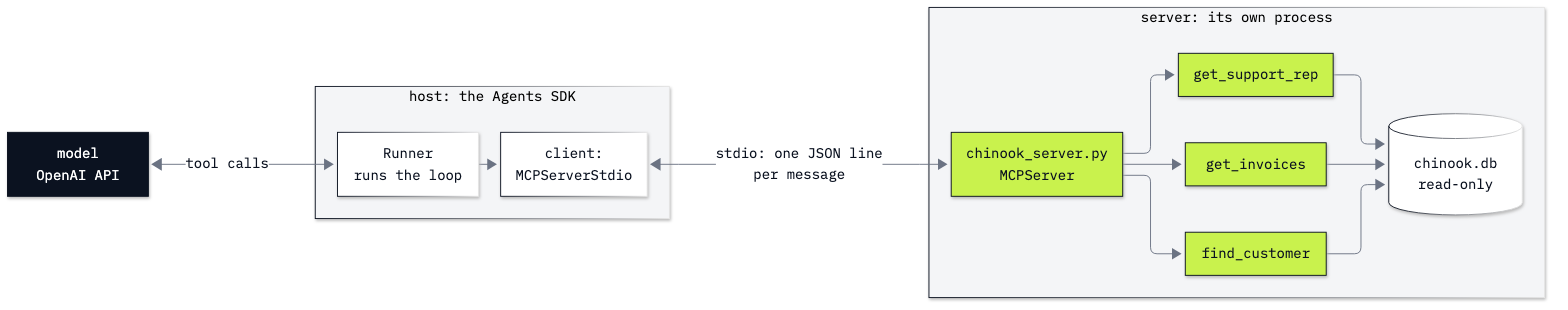

In [18]:
from IPython.display import Image

Image(filename="resources/lab06_mcp_host_client_server.png", width=760)

Read it from left to right:

- The model (the dark box) only exchanges messages with the host. It never sees the server.
- The host is the Agents SDK. Its `Runner` runs the loop, and its client, `MCPServerStdio`, started
  `chinook_server.py` as a separate process and exchanged lines of JSON with it.
- The lime boxes are our code: the server file and its three lookups. We did not change a character of it for the
  SDK.

**Key lesson:** the server's code does not depend on which program calls it, and the host's code does not contain
the lookups. The three lookups are written once, in one file, and every program that speaks MCP can use them: the
Inspector, a loop of our own like notebook 1's, this SDK, an assistant in an editor.

**Checkpoint C.** After the deletion, none of the five names is left in the notebook. The SDK's answer has 7
invoices, \$49.62 and Steve Johnson. `new_items` shows three calls to our server, `find_customer` first, and all
three checks print ✅.

---

## Going further

- **Other hosts.** Most agent frameworks, and many desktop assistants and code editors, can use an MCP server.
  Each needs the same two things we gave the SDK: the command and the arguments that start the server.
- **A server on another machine.** Stdio is for a server on the same machine as its host. A remote server uses
  the transport called **Streamable HTTP**, the same JSON messages sent as HTTP requests, and it needs what any
  web service needs: authentication, and care about what data is sent to it.
- **A server is code you run, and its text reaches the model.** A stdio server from the internet runs with your
  permissions. A tool's description and its results are text the model reads, and a server can put instructions
  there as easily as data. Read a server before you start it, pin its version, and give it read-only access where
  you can, as `chinook_server.py` does.
- **The messages themselves.** `06_extra_on_the_wire.ipynb` writes MCP requests by hand: the envelope every
  request carries, the two errors a request without it gets, and why a server must never `print()` to its standard
  output.

## What you can do now

- Read an MCP server file and say where each tool's name, description, arguments and result shape come from
  (Part B).
- Say what the server builds from a typed function that our own loop needed typed by hand (Parts A and B).
- Call a server with `mcp.Client`, read `content`, `structuredContent` and `isError`, and handle a lookup that
  finds nobody (Part B).
- Give a server to the Agents SDK with `MCPServerStdio` and `mcp_servers`, and check in `new_items` that the
  answer came from the server's tools (Part C).

## Troubleshooting

| What you see | Why | Fix |
|---|---|---|
| `ExceptionGroup: unhandled errors in a TaskGroup (1 sub-exception)` when a `Client` block starts | the server process did not start: a wrong path to the server file, or a Python without `mcp` | start it with `sys.executable` and the path in `SERVER_FILE`; the terminal that runs Jupyter shows the server's own error |
| ``UserError: Server not initialized. Make sure you call `connect()` first.`` | `Runner.run` was called outside `async with chinook:` | put the run inside the `async with` block, which connects the server |
| `NameError: name 'TOOLS' is not defined` when `ask` is called after Part C | Part C deleted the notebook's lookups on purpose | run the notebook from the top to get them back |
| `SyntaxError: 'await' outside function` in a `.py` file | `await` outside a function works in a notebook only | put the code in `async def main()` and run it with `asyncio.run(main())` |

## Challenge

Give the desk a fourth lookup without touching the host.

1. Copy `chinook_server.py` to a new file in this folder and add `get_recent_invoices(customer_id: int, limit: int = 3)`.
   It returns the customer's most recent invoices, newest first, as a list of `TypedDict` records with `invoice_id`,
   `date` (`date(InvoiceDate)` in SQL gives `YYYY-MM-DD`) and `total`. The `invoices` table has the columns
   `InvoiceId`, `CustomerId`, `InvoiceDate` and `Total`, among others. List the copy's tools with `mcp.Client`.
   Expected: four tools, and in the new tool's `input_schema` a `limit` with `"default": 3` that is not in
   `required`. Call it by hand for customer 6. Expected: invoices 404 (2013-11-13, 25.86), 393 (2013-10-03, 1.98)
   and 272 (2012-04-11, 0.99), as three content blocks, one per invoice.
2. Point a new `MCPServerStdio` at your copy, give it to a new `Agent`, and ask: *What were Helena Holý's three most
   recent invoices?* Expected: a call to `find_customer`, then to `get_recent_invoices` with `customer_id` 6, and an
   answer with the three dates and totals. Does the reply also give the invoice numbers? To see the calls and what came back, reuse the cell of Part C that prints `new_items`. It joins every block, and here
the new tool's result arrives as a list of three blocks.

The worked solution, run with its outputs, is in `solved/06b_mcp_at_the_desk_solution.ipynb`; its server is
`solved/chinook_server_plus.py`.

## Resources

- [MCP: architecture overview](https://modelcontextprotocol.io/docs/2026-07-28/learn/architecture): hosts, clients
  and servers
- [MCP Python SDK documentation](https://py.sdk.modelcontextprotocol.io/): `MCPServer`, `@mcp.tool()`, `Client`
- [OpenAI Agents SDK: MCP](https://openai.github.io/openai-agents-python/mcp/): `MCPServerStdio` and the other
  server classes
- [MCP security best practices](https://modelcontextprotocol.io/docs/2026-07-28/tutorials/security/security_best_practices)
  and [the MCP Registry](https://modelcontextprotocol.io/registry/about): what to check before you install a server
- [Python: `typing.TypedDict`](https://docs.python.org/3/library/typing.html#typing.TypedDict)

Back to [notebook 1](06a_meet_mcp.ipynb), or on to the extra notebook,
[MCP messages by hand](06_extra_on_the_wire.ipynb).